In [2]:
!pip install -q ucimlrepo

In [3]:
from ucimlrepo import fetch_ucirepo
online_retail = fetch_ucirepo(id=352)
df = online_retail.data.features
print(df.head())

                           Description  Quantity     InvoiceDate  UnitPrice  \
0   WHITE HANGING HEART T-LIGHT HOLDER         6  12/1/2010 8:26       2.55   
1                  WHITE METAL LANTERN         6  12/1/2010 8:26       3.39   
2       CREAM CUPID HEARTS COAT HANGER         8  12/1/2010 8:26       2.75   
3  KNITTED UNION FLAG HOT WATER BOTTLE         6  12/1/2010 8:26       3.39   
4       RED WOOLLY HOTTIE WHITE HEART.         6  12/1/2010 8:26       3.39   

   CustomerID         Country  
0     17850.0  United Kingdom  
1     17850.0  United Kingdom  
2     17850.0  United Kingdom  
3     17850.0  United Kingdom  
4     17850.0  United Kingdom  


In [4]:
print(df.shape)
print(df.columns)
print(df.info())

(541909, 6)
Index(['Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID',
       'Country'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Description  540455 non-null  object 
 1   Quantity     541909 non-null  int64  
 2   InvoiceDate  541909 non-null  object 
 3   UnitPrice    541909 non-null  float64
 4   CustomerID   406829 non-null  float64
 5   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 24.8+ MB
None


In [6]:
import pandas as pd

In [7]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print(df['InvoiceDate'].dtype)
print(df['InvoiceDate'].head())

datetime64[ns]
0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[ns]


/tmp/ipykernel_1177/4265185218.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])


In [8]:
df = df.copy()
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print(df['InvoiceDate'].dtype)

datetime64[ns]


In [9]:
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
print(df[['InvoiceDate', 'Year', 'Month']].head())

          InvoiceDate  Year  Month
0 2010-12-01 08:26:00  2010     12
1 2010-12-01 08:26:00  2010     12
2 2010-12-01 08:26:00  2010     12
3 2010-12-01 08:26:00  2010     12
4 2010-12-01 08:26:00  2010     12


In [10]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']
print(df[['Quantity', 'UnitPrice', 'Revenue']].head())

   Quantity  UnitPrice  Revenue
0         6       2.55    15.30
1         6       3.39    20.34
2         8       2.75    22.00
3         6       3.39    20.34
4         6       3.39    20.34


In [11]:
monthly_revenue = df.groupby(['Year', 'Month'])['Revenue'].sum().reset_index()
print(monthly_revenue)

    Year  Month      Revenue
0   2010     12   748957.020
1   2011      1   560000.260
2   2011      2   498062.650
3   2011      3   683267.080
4   2011      4   493207.121
5   2011      5   723333.510
6   2011      6   691123.120
7   2011      7   681300.111
8   2011      8   682680.510
9   2011      9  1019687.622
10  2011     10  1070704.670
11  2011     11  1461756.250
12  2011     12   433668.010


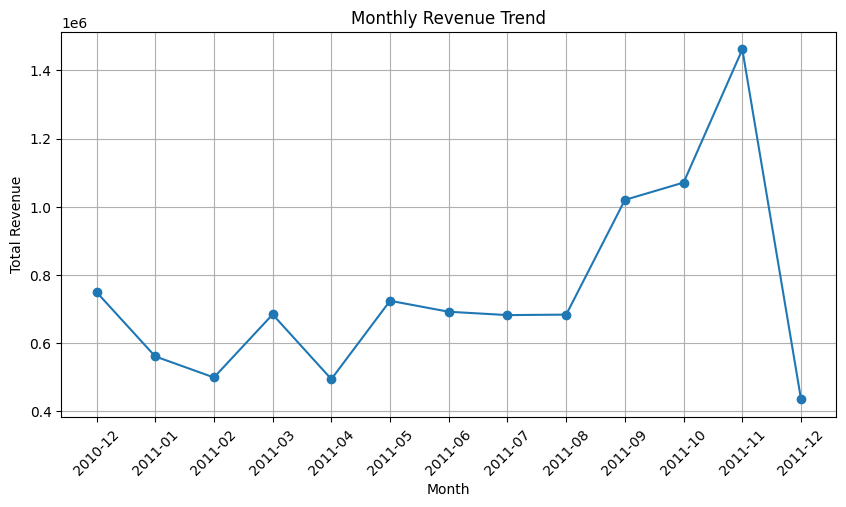

In [12]:
import matplotlib.pyplot as plt
monthly_revenue['Period'] = (
    monthly_revenue['Year'].astype(str)
    + '-'
    + monthly_revenue['Month'].astype(str).str.zfill(2)
)
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_revenue['Period'],
    monthly_revenue['Revenue'],
    marker='o'
)
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [13]:
country_revenue = (
    df.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
)
print(country_revenue.head(10))

Country
United Kingdom    8187806.364
Netherlands        284661.540
EIRE               263276.820
Germany            221698.210
France             197403.900
Australia          137077.270
Switzerland         56385.350
Spain               54774.580
Belgium             40910.960
Sweden              36595.910
Name: Revenue, dtype: float64


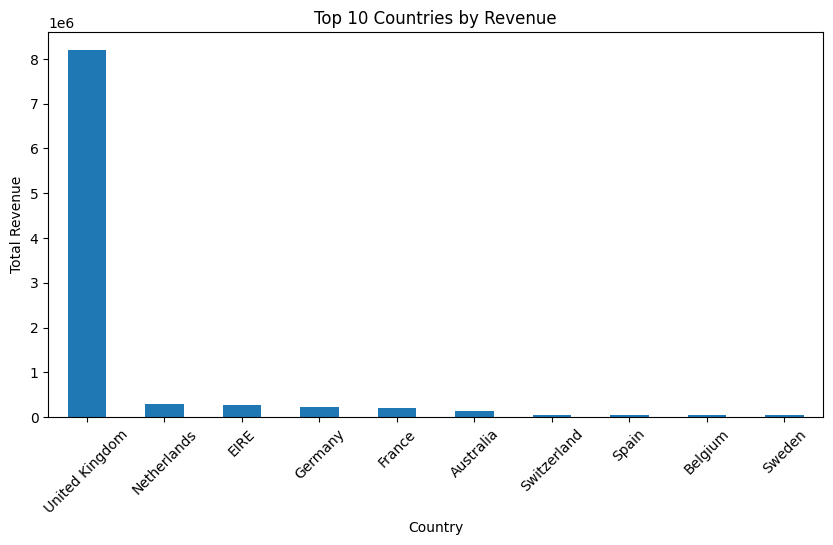

In [14]:
top_countries = country_revenue.head(10)
plt.figure(figsize=(10, 5))
top_countries.plot(kind='bar')
plt.title('Top 10 Countries by Revenue')
plt.xlabel('Country')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()

In [15]:
pivot_revenue = pd.pivot_table(
    df,
    values='Revenue',
    index='Country',
    columns='Year',
    aggfunc='sum'
)
print(pivot_revenue)

Year                       2010         2011
Country                                     
Australia               1005.10   136072.170
Austria                  257.04     9897.280
Bahrain                  205.74      342.660
Belgium                 1809.91    39101.050
Brazil                      NaN     1143.600
Canada                      NaN     3666.380
Channel Islands          363.53    19722.760
Cyprus                  1590.82    11355.470
Czech Republic              NaN      707.720
Denmark                 1281.50    17486.640
EIRE                    9029.95   254246.870
European Community          NaN     1291.750
Finland                  892.80    21433.940
France                  9575.36   187828.540
Germany                14562.84   207135.370
Greece                      NaN     4710.520
Hong Kong                   NaN    10117.040
Iceland                  711.79     3598.210
Israel                  -227.44     8135.260
Italy                    794.50    16096.010
Japan     

In [16]:
customer_revenue = (
    df.dropna(subset=['CustomerID'])
      .groupby('CustomerID')['Revenue']
      .sum()
      .sort_values(ascending=False)
)
print(customer_revenue.head(10))

CustomerID
14646.0    279489.02
18102.0    256438.49
17450.0    187482.17
14911.0    132572.62
12415.0    123725.45
14156.0    113384.14
17511.0     88125.38
16684.0     65892.08
13694.0     62653.10
15311.0     59419.34
Name: Revenue, dtype: float64


In [17]:
q25 = customer_revenue.quantile(0.25)
q75 = customer_revenue.quantile(0.75)
def segment_customer(revenue):
    if revenue >= q75:
        return 'High Value'
    elif revenue >= q25:
        return 'Medium Value'
    else:
        return 'Low Value'
customer_segments = customer_revenue.apply(segment_customer)
print(customer_segments.value_counts())

Revenue
Medium Value    2186
High Value      1093
Low Value       1093
Name: count, dtype: int64


In [18]:
segment_revenue = (
    customer_revenue.groupby(customer_segments)
    .sum()
    .sort_values(ascending=False)
)
print(segment_revenue)

Revenue
High Value      6520014.571
Medium Value    1615108.273
Low Value        164942.970
Name: Revenue, dtype: float64


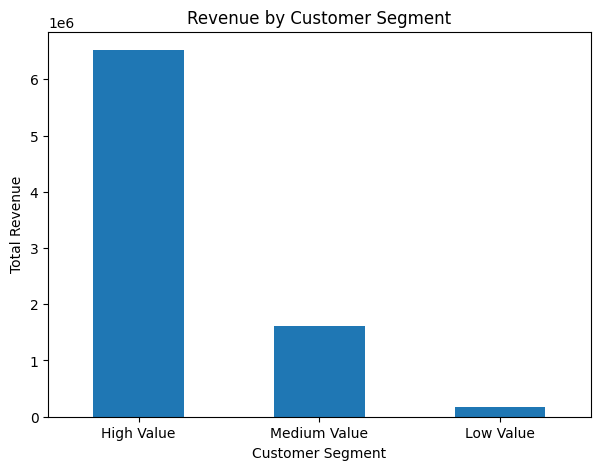

In [19]:
plt.figure(figsize=(7, 5))
segment_revenue.plot(kind='bar')
plt.title('Revenue by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.show()

In [20]:
monthly_revenue['Revenue_Change'] = monthly_revenue['Revenue'].pct_change() * 100
print(monthly_revenue)

    Year  Month      Revenue   Period  Revenue_Change
0   2010     12   748957.020  2010-12             NaN
1   2011      1   560000.260  2011-01      -25.229320
2   2011      2   498062.650  2011-02      -11.060282
3   2011      3   683267.080  2011-03       37.184967
4   2011      4   493207.121  2011-04      -27.816350
5   2011      5   723333.510  2011-05       46.659178
6   2011      6   691123.120  2011-06       -4.453048
7   2011      7   681300.111  2011-07       -1.421311
8   2011      8   682680.510  2011-08        0.202612
9   2011      9  1019687.622  2011-09       49.365275
10  2011     10  1070704.670  2011-10        5.003204
11  2011     11  1461756.250  2011-11       36.522824
12  2011     12   433668.010  2011-12      -70.332399


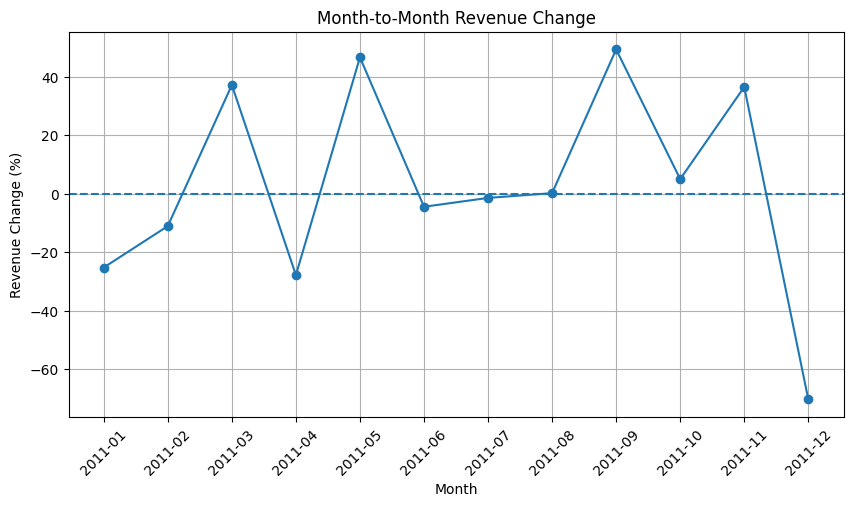

In [21]:
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_revenue['Period'],
    monthly_revenue['Revenue_Change'],
    marker='o'
)
plt.axhline(0, linestyle='--')
plt.title('Month-to-Month Revenue Change')
plt.xlabel('Month')
plt.ylabel('Revenue Change (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

## Actionable Business Recommendations

1. **Focus on High-Value Customers:** Develop loyalty benefits and personalized offers to improve retention of high-value customers.

2. **Use Revenue Trends:** Analyze high-revenue months and identify the products, promotions, or seasonal factors contributing to increased sales.

3. **Investigate Revenue Drops:** Review months with significant revenue decreases to identify possible seasonal effects, product availability issues, or changes in sales activity.

4. **Focus on Top Markets:** Prioritize marketing and customer-retention activities in countries generating higher revenue.

5. **Use Customer Segmentation:** Create different marketing strategies and offers for High Value, Medium Value, and Low Value customer segments.
